<a href="https://colab.research.google.com/github/uw-24-ai-bs-027/titanic-data-analysis/blob/main/Titanic_Data_Cleaning_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Titanic Passenger Data: Cleaning and Analysis

## Project Overview
This project cleans and analyzes the Titanic passenger dataset to understand which factors influenced survival. It covers data inspection, missing value handling, and visual analysis using Python.

## Dataset
- **Source:** Titanic dataset from the Seaborn library
- **Size:** 891 passengers, 15 columns
- **Key columns:** survived, pclass, sex, age, fare, embarked, class

## Tools Used
Python, Pandas, Seaborn, Matplotlib, Google Colab

## Data Cleaning Steps
1. **Age:** 177 missing values filled with the median age.
2. **Embarked / Embark town:** 2 missing values filled with the most frequent value (mode).
3. **Deck:** Column removed because about 77% of its values were missing.
4. **Duplicates:** 116 duplicate-looking rows were kept, since they represent different passengers with similar details.

## Key Findings
- Women had a much higher survival rate than men.
- Survival rate dropped from First to Third class.
- Most passengers were aged 20-35.

In [15]:
import pandas as pd
import seaborn as sns

df = sns.load_dataset("titanic")
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [9]:
print(df.shape)
print(df.info())
print(df.isnull().sum())

(891, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB
None
survived         0
pclass           0
sex              0
age    

In [10]:

df['age'] = df['age'].fillna(df['age'].median())

df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])
df['embark_town'] = df['embark_town'].fillna(df['embark_town'].mode()[0])


df = df.drop(columns=['deck'])


print(df.isnull().sum())

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
dtype: int64


In [11]:
print(df.duplicated().sum())

116


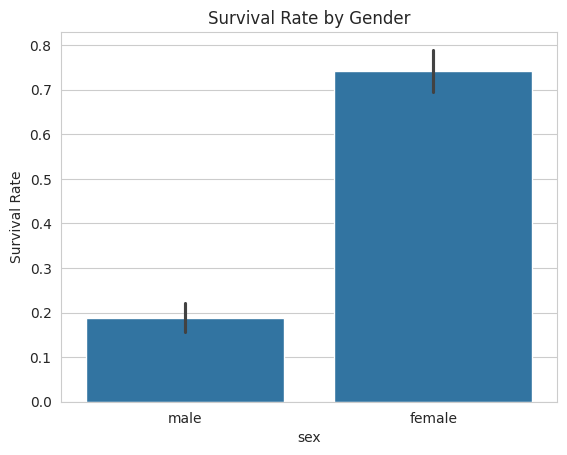

In [12]:
import matplotlib.pyplot as plt

sns.set_style("whitegrid")


sns.barplot(x='sex', y='survived', data=df)
plt.title('Survival Rate by Gender')
plt.ylabel('Survival Rate')
plt.show()

Female passengers had a much higher survival rate (about 74%) than male passengers (about 19%), suggesting women were prioritized during evacuation.

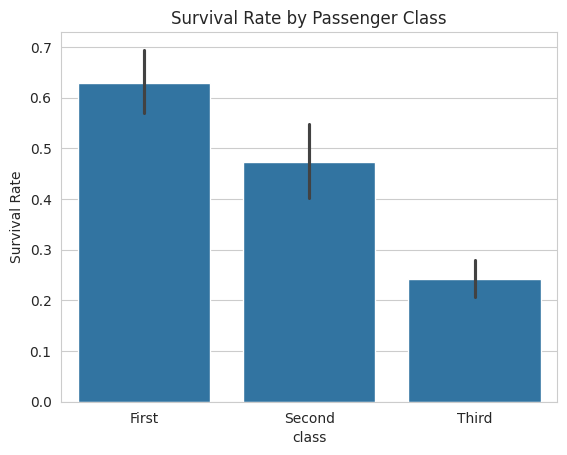

In [13]:

sns.barplot(x='class', y='survived', data=df)
plt.title('Survival Rate by Passenger Class')
plt.ylabel('Survival Rate')
plt.show()

Survival rate dropped steadily with class: about 63% for First, 47% for Second, and only 24% for Third class, showing that higher-class passengers had a better chance of survival.

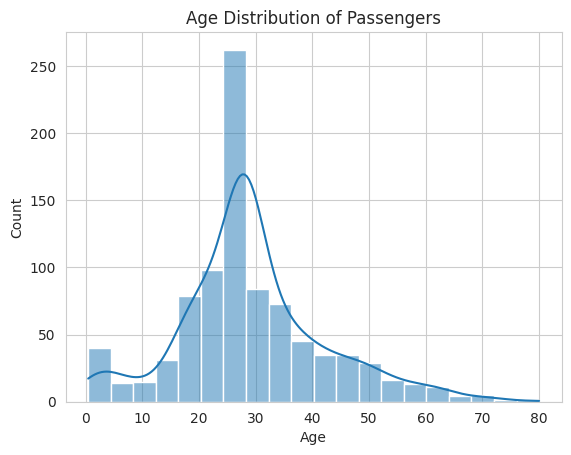

In [14]:

sns.histplot(df['age'], bins=20, kde=True)
plt.title('Age Distribution of Passengers')
plt.xlabel('Age')
plt.show()

Most passengers were between 20 and 35 years old, with a sharp peak around age 28. A smaller group of young children (under 10) is also visible, while older passengers (50+) are relatively few.

Note: The peak near age 28 is partly caused by filling 177 missing age values with the median.